## AG3 - Actividad Guiada 3
Nombre: Guido Quispe Quispe <br>
Link:   
Github: https://github.com/Guidouib/Algoritmos_de_Optimizacion/tree/main/AG3%20-%20Actividad%20Guiada%203
<br>

# Algoritmos de búsqueda aplicados al Problema del Viajante (TSP)

**Objetivo de la actividad**

- Desarrollar algoritmos con la técnica de **búsqueda aleatoria**
- Desarrollar algoritmos con la técnica de **búsqueda local**
- Desarrollar algoritmos con la técnica de **recocido simulado** (*simulated annealing*)
- Desarrollar algoritmos con la técnica de **colonia de hormigas** (no evaluable)

**Problema:** instancia `swiss42` de TSPLIB (42 ciudades de Suiza, matriz de distancias explícita y simétrica).
Se busca el recorrido cerrado de menor longitud que visite cada ciudad una sola vez, comenzando en el nodo 0.
El óptimo conocido de esta instancia es **1273**, que se usa como referencia para medir la calidad (*gap*) de cada técnica.

**Mejoras realizadas sobre la plantilla de la actividad**

| Parte | Plantilla original | Versión mejorada |
|---|---|---|
| Carga de datos | `!pip` con comentario en la línea (falla) y `!gzip` (no existe en Windows) | Instalación condicional y descarga/descompresión con Python, con servidor alternativo |
| Distancias | `problem.get_weight()` en cada evaluación | Matriz de distancias precalculada `D` (mucho más rápida) |
| Búsqueda aleatoria | Solo la mejor solución | Además, historial de convergencia y estadística de las soluciones aleatorias |
| Búsqueda local | Vecindario de **intercambio** de 2 nodos (llamado 2-opt) | Se conserva como referencia y se añade el **2-opt real** (inversión de tramo) con evaluación incremental O(1) y **multiarranque** |
| Recocido simulado | T₀ = 10⁷ (≈40 % de iteraciones son paseo aleatorio), solo ~2 500 iteraciones | T₀ **calibrada** con la tasa de aceptación inicial, **L iteraciones por temperatura**, vecino 2-opt, estudio de sensibilidad del enfriamiento y pulido final |
| Colonia de hormigas | Elección uniforme del siguiente nodo, matriz de feromonas transpuesta al evaporar | Regla de transición probabilística τ^α·η^β, evaporación correcta y depósito en ambos sentidos |

# Carga de librerías

In [1]:
# Instalación de librerías solo si faltan.
# Nota: en la plantilla original "!pip install requests  #Hacer ..." fallaba porque pip
# interpreta el comentario de la misma línea como un nombre de paquete.
import importlib, subprocess, sys

for paquete in ["tsplib95", "matplotlib"]:
    try:
        importlib.import_module(paquete)
        print(f"{paquete}: ya instalado")
    except ImportError:
        print(f"Instalando {paquete}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

tsplib95: ya instalado
matplotlib: ya instalado


In [2]:
import os                  # Comprobar si el fichero de datos existe
import gzip                # Descomprimir .gz sin depender del comando gzip (Windows)
import math                # exp() para el recocido simulado
import random              # Generación de valores aleatorios
import time                # Medición de tiempos de ejecución
import statistics          # Media y desviación de los experimentos
import urllib.request      # Descarga del fichero de datos
import tsplib95            # Instancias del problema TSP
import matplotlib.pyplot as plt

# Carga de los datos del problema

Se intenta usar el fichero local; si no existe, se descarga primero del servidor oficial de TSPLIB
y, si este no responde (error de *timeout* que ocurría en la versión original), de un repositorio espejo en GitHub.
La descompresión se hace con el módulo `gzip` de Python para que funcione igual en Windows, Linux y Colab.

In [3]:
FICHERO = "swiss42.tsp"
URLS = [
    "http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/swiss42.tsp.gz",   # Servidor oficial TSPLIB
    "https://raw.githubusercontent.com/mastqe/tsplib/master/swiss42.tsp",       # Espejo en GitHub
]

def obtener_fichero(fichero=FICHERO, urls=URLS):
    if os.path.exists(fichero):
        print("Usando el fichero local:", fichero)
        return
    for url in urls:
        try:
            datos = urllib.request.urlopen(url, timeout=15).read()
            if url.endswith(".gz"):
                datos = gzip.decompress(datos)
            with open(fichero, "wb") as f:
                f.write(datos)
            print("Fichero descargado de:", url)
            return
        except Exception as e:
            print("No se pudo descargar de", url, "->", type(e).__name__)
    raise FileNotFoundError("No se pudo obtener " + fichero + ". Descárgalo manualmente y colócalo junto al notebook.")

obtener_fichero()

# Carga de datos y generación del objeto problem
problem = tsplib95.load(FICHERO)

# Nodos
Nodos = list(problem.get_nodes())
N_NODOS = len(Nodos)

# Aristas
Aristas = list(problem.get_edges())

# Matriz de distancias precalculada: se consulta millones de veces, así evitamos llamar a get_weight()
D = [[problem.get_weight(i, j) for j in Nodos] for i in Nodos]

OPTIMO = 1273   # Óptimo conocido de swiss42 (TSPLIB)

print("Instancia :", problem.name, "-", problem.comment)
print("Nodos     :", N_NODOS, " (de", Nodos[0], "a", Nodos[-1], ")")
print("Aristas   :", len(Aristas))
print("Distancia entre el nodo 0 y el 1:", problem.get_weight(0, 1))

No se pudo descargar de http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/tsp/swiss42.tsp.gz -> URLError
Fichero descargado de: https://raw.githubusercontent.com/mastqe/tsplib/master/swiss42.tsp
Instancia : swiss42 - 42 Staedte Schweiz (Fricker)
Nodos     : 42  (de 0 a 41 )
Aristas   : 1764
Distancia entre el nodo 0 y el 1: 15


# Funciones básicas

In [4]:
# Se genera una solución aleatoria con comienzo en el nodo 0 (igual que en la plantilla)
def crear_solucion(Nodos):
    solucion = [Nodos[0]]
    for n in Nodos[1:]:
        solucion = solucion + [random.choice(list(set(Nodos) - set({Nodos[0]}) - set(solucion)))]
    return solucion

# Devuelve la distancia entre dos nodos (consulta la matriz precalculada)
def distancia(a, b, problem=None):
    return D[a][b]

# Devuelve la distancia total de una trayectoria/solución (incluye la vuelta al origen)
def distancia_total(solucion, problem=None):
    total = 0
    for i in range(len(solucion) - 1):
        total += D[solucion[i]][solucion[i + 1]]
    return total + D[solucion[-1]][solucion[0]]

# Comprueba que la solución es un recorrido válido: empieza en 0 y visita todos los nodos una vez
def es_valida(solucion):
    return solucion[0] == Nodos[0] and sorted(solucion) == sorted(Nodos)

# Distancia relativa al óptimo conocido (%)
def gap(d):
    return 100 * (d - OPTIMO) / OPTIMO

# Almacén de resultados para la comparación final
RESULTADOS = {}

def registrar(nombre, solucion, d, segundos):
    assert es_valida(solucion), "Solución no válida"
    assert d == distancia_total(solucion), "La distancia acumulada no coincide con la real"
    RESULTADOS[nombre] = {"distancia": d, "tiempo": segundos, "solucion": solucion}
    print(f"{nombre}: distancia = {d}  |  gap = {gap(d):.2f} %  |  tiempo = {segundos:.2f} s")

random.seed(0)
sol_temporal = crear_solucion(Nodos)
print(distancia_total(sol_temporal, problem), sol_temporal)

4507 [0, 25, 28, 3, 18, 37, 36, 30, 22, 39, 27, 21, 40, 8, 20, 6, 13, 7, 5, 34, 15, 33, 41, 10, 14, 35, 2, 31, 29, 23, 11, 17, 24, 1, 16, 9, 38, 26, 19, 12, 4, 32]


# 1. Búsqueda aleatoria

Se generan `N` soluciones completamente aleatorias y se conserva la mejor. No usa ninguna información
del problema, por lo que sirve como **línea base**: cualquier técnica "inteligente" debería superarla con claridad.

Respecto a la plantilla se añade el historial de la mejor distancia (para ver la convergencia) y la estadística
de las soluciones generadas, que muestra lo lejos que está una solución típica al azar del óptimo.

In [5]:
###############################################################################
# BUSQUEDA ALEATORIA
###############################################################################
def busqueda_aleatoria(problem, N, semilla=None):
    # N es el número de iteraciones
    if semilla is not None:
        random.seed(semilla)
    Nodos = list(problem.get_nodes())

    mejor_solucion = []
    mejor_distancia = float('inf')       # Inicializamos con un valor alto
    historial = []                       # Mejor distancia tras cada iteración
    distancias = []                      # Distancia de cada solución generada

    for i in range(N):                                 # Criterio de parada: repetir N veces
        solucion = crear_solucion(Nodos)               # Genera una solución aleatoria
        d = distancia_total(solucion, problem)         # Calcula el valor objetivo (distancia total)
        distancias.append(d)
        if d < mejor_distancia:                        # Compara con la mejor obtenida hasta ahora
            mejor_solucion = solucion
            mejor_distancia = d
        historial.append(mejor_distancia)

    return mejor_solucion, mejor_distancia, historial, distancias


# Búsqueda aleatoria con 10 000 iteraciones
inicio = time.perf_counter()
sol_aleatoria, dist_aleatoria, hist_aleatoria, todas_aleatorias = busqueda_aleatoria(problem, 10000, semilla=1)
t = time.perf_counter() - inicio

print("Mejor solución:", sol_aleatoria)
print(f"Distancia media de una solución aleatoria: {statistics.mean(todas_aleatorias):.1f} "
      f"(desv. {statistics.stdev(todas_aleatorias):.1f})")
registrar("Búsqueda aleatoria", sol_aleatoria, dist_aleatoria, t)

Mejor solución: [0, 16, 12, 8, 29, 4, 25, 26, 10, 28, 37, 1, 30, 2, 39, 19, 41, 11, 17, 31, 33, 34, 20, 22, 21, 9, 40, 24, 7, 38, 35, 32, 18, 3, 23, 5, 13, 27, 6, 14, 15, 36]
Distancia media de una solución aleatoria: 4830.0 (desv. 289.3)
Búsqueda aleatoria: distancia = 3730  |  gap = 193.01 %  |  tiempo = 1.49 s


# 2. Búsqueda local

La búsqueda local parte de una solución y se mueve repetidamente a la **mejor solución vecina**
mientras mejore. Se detiene al llegar a un **óptimo local**: ningún vecino es mejor.
La calidad depende mucho del **operador de vecindad**.

### 2.1 Versión de la plantilla: vecindario de intercambio (*swap*)

El operador de la plantilla intercambia la posición de dos nodos. Aunque en los comentarios se llama 2-opt,
en realidad es un *swap*: al cambiar dos ciudades se rompen hasta **4 aristas** del recorrido, lo que
genera movimientos muy bruscos. Se mantiene como referencia, corrigiendo que la función devolviera
una lista vacía si la solución inicial ya era un óptimo local.

In [6]:
###############################################################################
# BUSQUEDA LOCAL - Vecindario de intercambio (versión de la plantilla)
###############################################################################
def genera_vecina(solucion, problem=None):
    # Generador de soluciones vecinas: intercambiar 2 nodos. Si hay N nodos se generan (N-1)x(N-2)/2 soluciones
    mejor_solucion = []
    mejor_distancia = 10e100
    for i in range(1, len(solucion) - 1):        # Doble bucle para evaluar todos los intercambios
        for j in range(i + 1, len(solucion)):
            vecina = solucion[:i] + [solucion[j]] + solucion[i+1:j] + [solucion[i]] + solucion[j+1:]
            distancia_vecina = distancia_total(vecina, problem)
            if distancia_vecina <= mejor_distancia:
                mejor_distancia = distancia_vecina
                mejor_solucion = vecina
    return mejor_solucion


def busqueda_local(problem, solucion_inicial=None, semilla=None):
    if semilla is not None:
        random.seed(semilla)
    # Generar una solución inicial de referencia (aleatoria si no se indica)
    solucion_referencia = solucion_inicial[:] if solucion_inicial else crear_solucion(Nodos)
    mejor_solucion = solucion_referencia            # Corrección: antes se inicializaba a []
    mejor_distancia = distancia_total(solucion_referencia, problem)

    iteracion = 0
    while True:
        iteracion += 1
        vecina = genera_vecina(solucion_referencia, problem)     # Mejor vecina ...
        distancia_vecina = distancia_total(vecina, problem)      # ... y su evaluación
        if distancia_vecina < mejor_distancia:
            mejor_solucion = vecina
            mejor_distancia = distancia_vecina
        else:
            # No mejora: hemos llegado a un mínimo local según el operador de vecindad
            return mejor_solucion, mejor_distancia, iteracion
        solucion_referencia = vecina


inicio = time.perf_counter()
sol_ls_swap, dist_ls_swap, it_ls_swap = busqueda_local(problem, semilla=2)
t = time.perf_counter() - inicio
print("Iteraciones hasta el óptimo local:", it_ls_swap)
print("Mejor solución:", sol_ls_swap)
registrar("Búsqueda local (swap)", sol_ls_swap, dist_ls_swap, t)

Iteraciones hasta el óptimo local: 43
Mejor solución: [0, 27, 28, 29, 39, 24, 40, 21, 9, 4, 16, 14, 1, 2, 30, 22, 38, 34, 33, 20, 32, 3, 18, 12, 11, 25, 41, 23, 8, 10, 13, 19, 15, 37, 17, 36, 35, 31, 7, 5, 26, 6]
Búsqueda local (swap): distancia = 1807  |  gap = 41.95 %  |  tiempo = 0.10 s


### 2.2 Mejora: búsqueda local con el operador 2-opt real

El **2-opt** elimina dos aristas `(a,b)` y `(c,d)` y reconecta el recorrido como `(a,c)` y `(b,d)`,
lo que equivale a **invertir el tramo** entre `b` y `c`. Solo cambian 2 aristas, por lo que es el
vecindario clásico para el TSP: elimina los cruces del recorrido.

Además, la variación de distancia se calcula de forma **incremental en O(1)**, sin recorrer toda la solución:

$$\Delta = d(a,c) + d(b,d) - d(a,b) - d(c,d)$$

Esto permite explorar el vecindario completo (≈ 820 vecinos) cientos de veces más rápido.

In [7]:
###############################################################################
# BUSQUEDA LOCAL - Operador 2-opt real con evaluación incremental
###############################################################################
def delta_2opt(s, i, j):
    # Variación de distancia al invertir el tramo s[i..j] (1 <= i < j <= n-1)
    n = len(s)
    a, b = s[i - 1], s[i]
    c, d = s[j], s[(j + 1) % n]
    return D[a][c] + D[b][d] - D[a][b] - D[c][d]


def aplicar_2opt(s, i, j):
    # Devuelve la solución con el tramo i..j invertido (el nodo 0 siempre queda en la posición 0)
    return s[:i] + s[i:j + 1][::-1] + s[j + 1:]


def mejor_movimiento_2opt(s):
    # Explora todo el vecindario 2-opt y devuelve el mejor movimiento que mejora (o None)
    mejor_delta, mejor_ij = 0, None
    n = len(s)
    for i in range(1, n - 1):
        for j in range(i + 1, n):
            dl = delta_2opt(s, i, j)
            if dl < mejor_delta:
                mejor_delta, mejor_ij = dl, (i, j)
    return mejor_ij, mejor_delta


def busqueda_local_2opt(problem, solucion_inicial=None, semilla=None):
    if semilla is not None:
        random.seed(semilla)
    s = solucion_inicial[:] if solucion_inicial else crear_solucion(Nodos)
    d = distancia_total(s, problem)
    iteraciones = 0
    while True:
        movimiento, dl = mejor_movimiento_2opt(s)
        if movimiento is None:              # Ningún vecino mejora: óptimo local 2-opt
            return s, d, iteraciones
        s = aplicar_2opt(s, *movimiento)
        d += dl
        iteraciones += 1


inicio = time.perf_counter()
sol_ls_2opt, dist_ls_2opt, it_ls_2opt = busqueda_local_2opt(problem, semilla=2)   # Misma semilla: mismo punto de partida
t = time.perf_counter() - inicio
print("Iteraciones hasta el óptimo local:", it_ls_2opt)
print("Mejor solución:", sol_ls_2opt)
registrar("Búsqueda local (2-opt)", sol_ls_2opt, dist_ls_2opt, t)

Iteraciones hasta el óptimo local: 35
Mejor solución: [0, 1, 6, 4, 3, 2, 27, 28, 8, 29, 30, 32, 20, 33, 34, 38, 22, 39, 21, 24, 40, 9, 23, 41, 10, 25, 11, 12, 18, 26, 5, 13, 19, 14, 16, 15, 37, 36, 35, 31, 17, 7]
Búsqueda local (2-opt): distancia = 1343  |  gap = 5.50 %  |  tiempo = 0.01 s


### 2.3 Mejora: búsqueda local 2-opt con multiarranque

La búsqueda local siempre se queda en el primer óptimo local que encuentra. Como es muy rápida,
se repite desde **muchas soluciones iniciales aleatorias** y se conserva la mejor. Así se combina la
exploración de la búsqueda aleatoria con la explotación de la búsqueda local.

In [8]:
def busqueda_local_multiarranque(problem, arranques=100, semilla=None):
    if semilla is not None:
        random.seed(semilla)
    mejor_s, mejor_d = None, float('inf')
    resultados = []
    for k in range(arranques):
        s, d, _ = busqueda_local_2opt(problem)
        resultados.append(d)
        if d < mejor_d:
            mejor_s, mejor_d = s, d
    return mejor_s, mejor_d, resultados


inicio = time.perf_counter()
sol_multi, dist_multi, dist_arranques = busqueda_local_multiarranque(problem, arranques=100, semilla=3)
t = time.perf_counter() - inicio
print(f"Óptimos locales encontrados: media = {statistics.mean(dist_arranques):.1f}, "
      f"peor = {max(dist_arranques)}, mejor = {min(dist_arranques)}")
print("Arranques que alcanzan el óptimo conocido:", dist_arranques.count(OPTIMO), "de", len(dist_arranques))
print("Mejor solución:", sol_multi)
registrar("Búsqueda local 2-opt multiarranque (100)", sol_multi, dist_multi, t)

Óptimos locales encontrados: media = 1354.0, peor = 1467, mejor = 1273
Arranques que alcanzan el óptimo conocido: 3 de 100
Mejor solución: [0, 1, 6, 4, 3, 27, 2, 28, 29, 30, 38, 22, 39, 24, 40, 21, 9, 23, 41, 8, 10, 25, 11, 12, 18, 26, 5, 13, 19, 14, 16, 15, 37, 7, 17, 31, 36, 35, 20, 33, 34, 32]
Búsqueda local 2-opt multiarranque (100): distancia = 1273  |  gap = 0.00 %  |  tiempo = 0.54 s


# 3. Recocido simulado (*simulated annealing*)

A diferencia de la búsqueda local, el recocido simulado **acepta soluciones peores** con una probabilidad
que depende de la temperatura `T` y del empeoramiento `Δ`:

$$P(\text{aceptar}) = e^{-\Delta / T}$$

Con `T` alta acepta casi todo (exploración) y, a medida que `T` baja, se comporta como una búsqueda local
(explotación). Esto le permite **escapar de óptimos locales**.

### 3.1 Versión de la plantilla

Se ejecuta tal cual (vecino por intercambio, T₀ = 10 000 000, enfriamiento `T·0.99`, parada en `T = 0.0001`).
El número de iteraciones queda fijado por estos parámetros:

$$\frac{\ln(10^{-4}/10^{7})}{\ln 0.99} \approx 2\,520 \text{ iteraciones}$$

y, como las diferencias de distancia son del orden de cientos, mientras `T` es muy superior a ese valor
se acepta prácticamente cualquier solución: el ~40 % de las iteraciones es un paseo aleatorio.

In [9]:
###############################################################################
# SIMULATED ANNEALING - Versión de la plantilla
###############################################################################
# Generador de 1 solución vecina por intercambio 100% aleatorio
def genera_vecina_aleatorio(solucion):
    i, j = sorted(random.sample(range(1, len(solucion)), 2))
    return solucion[:i] + [solucion[j]] + solucion[i+1:j] + [solucion[i]] + solucion[j+1:]

# Función de probabilidad para aceptar peores soluciones
def probabilidad(T, d):
    return random.random() < math.exp(-1 * d / T)

# Función de descenso de temperatura
def bajar_temperatura(T):
    return T * 0.99


def recocido_simulado(problem, TEMPERATURA, semilla=None):
    if semilla is not None:
        random.seed(semilla)
    solucion_referencia = crear_solucion(Nodos)
    distancia_referencia = distancia_total(solucion_referencia, problem)

    mejor_solucion = []             # x* del pseudocódigo
    mejor_distancia = 10e100        # F* del pseudocódigo
    historial = []

    N = 0
    while TEMPERATURA > .0001:
        N += 1
        vecina = genera_vecina_aleatorio(solucion_referencia)     # Genera una solución vecina
        distancia_vecina = distancia_total(vecina, problem)       # Calcula su valor (distancia)

        if distancia_vecina < mejor_distancia:                    # Si es la mejor de todas se guarda
            mejor_solucion = vecina
            mejor_distancia = distancia_vecina

        # Si la vecina es mejor se acepta; si es peor, según una probabilidad que depende de T y delta
        if distancia_vecina < distancia_referencia or probabilidad(TEMPERATURA, abs(distancia_referencia - distancia_vecina)):
            solucion_referencia = vecina
            distancia_referencia = distancia_vecina

        TEMPERATURA = bajar_temperatura(TEMPERATURA)               # Bajamos la temperatura
        historial.append(mejor_distancia)

    return mejor_solucion, mejor_distancia, N, historial


inicio = time.perf_counter()
sol_rs_orig, dist_rs_orig, it_rs_orig, hist_rs_orig = recocido_simulado(problem, 10000000, semilla=4)
t = time.perf_counter() - inicio
print("Iteraciones realizadas:", it_rs_orig)
print("Mejor solución:", sol_rs_orig)
registrar("Recocido simulado (plantilla)", sol_rs_orig, dist_rs_orig, t)

Iteraciones realizadas: 2521
Mejor solución: [0, 1, 13, 19, 6, 3, 2, 39, 22, 38, 17, 36, 35, 31, 7, 27, 20, 33, 34, 30, 28, 29, 9, 23, 41, 10, 8, 40, 24, 21, 32, 15, 37, 16, 14, 11, 25, 12, 18, 5, 26, 4]
Recocido simulado (plantilla): distancia = 2121  |  gap = 66.61 %  |  tiempo = 0.01 s


### 3.2 Mejora: recocido simulado calibrado con vecindario 2-opt

Cambios introducidos y su justificación:

1. **Vecino 2-opt aleatorio** con evaluación incremental O(1) (en lugar del intercambio), por las razones vistas en 2.2.
2. **Temperatura inicial calibrada**: se muestrean movimientos que empeoran y se elige T₀ para que la
   probabilidad de aceptar un empeoramiento medio sea del 80 %: $T_0 = -\overline{\Delta^+} / \ln(0.8)$.
   Así no se desperdician iteraciones en un paseo aleatorio.
3. **L iteraciones por nivel de temperatura** (`L = 10·n`), para que el sistema se "estabilice" en cada temperatura
   antes de enfriar. La plantilla solo hacía una.
4. **Enfriamiento geométrico** `T ← α·T` hasta `T_final = 0.5`, con estudio de sensibilidad de `α`.
5. **Pulido final** de la mejor solución con la búsqueda local 2-opt (asegura que el resultado es un óptimo local).

In [10]:
###############################################################################
# SIMULATED ANNEALING - Versión mejorada
###############################################################################
def vecina_2opt_aleatoria(s):
    # Elige un movimiento 2-opt al azar y devuelve (i, j, delta) sin construir aún la solución
    i, j = sorted(random.sample(range(1, len(s)), 2))
    return i, j, delta_2opt(s, i, j)


def temperatura_inicial(s, aceptacion=0.8, muestras=1000):
    # T0 tal que un empeoramiento medio se acepte con probabilidad 'aceptacion'
    empeoramientos = []
    for _ in range(muestras):
        _, _, dl = vecina_2opt_aleatoria(s)
        if dl > 0:
            empeoramientos.append(dl)
    return -statistics.mean(empeoramientos) / math.log(aceptacion)


def recocido_simulado_mejorado(problem, alfa=0.99, L=None, T_final=0.5, aceptacion_inicial=0.8, semilla=None):
    if semilla is not None:
        random.seed(semilla)
    L = L or 10 * N_NODOS

    s = crear_solucion(Nodos)
    d = distancia_total(s, problem)
    mejor_s, mejor_d = s, d

    T = T0 = temperatura_inicial(s, aceptacion_inicial)
    evaluaciones, historial = 0, []          # historial: (evaluaciones, mejor distancia) por nivel de T

    while T > T_final:
        for _ in range(L):                   # L iteraciones en cada nivel de temperatura
            i, j, dl = vecina_2opt_aleatoria(s)
            evaluaciones += 1
            if dl <= 0 or random.random() < math.exp(-dl / T):
                s = aplicar_2opt(s, i, j)
                d += dl
                if d < mejor_d:
                    mejor_s, mejor_d = s, d
        historial.append((evaluaciones, mejor_d))
        T *= alfa                            # Enfriamiento geométrico

    # Pulido final con búsqueda local 2-opt
    mejor_s, mejor_d, _ = busqueda_local_2opt(problem, mejor_s)
    return mejor_s, mejor_d, {"T0": T0, "evaluaciones": evaluaciones, "historial": historial}

#### Estudio de sensibilidad del factor de enfriamiento α

Al ser un algoritmo estocástico, un único resultado no es representativo. Para cada valor de `α`
se realizan **5 ejecuciones con semillas distintas** y se comparan la media, la mejor y el tiempo.

In [11]:
semillas = [10, 11, 12, 13, 14]
sensibilidad = {}
print(f"{'alfa':>6} | {'media':>7} | {'mejor':>5} | {'peor':>5} | {'nº óptimos':>10} | {'evaluaciones':>12} | {'tiempo/ejec.':>12}")
print("-" * 78)
for alfa in [0.90, 0.95, 0.99, 0.995]:
    dists, tiempos = [], []
    for sem in semillas:
        inicio = time.perf_counter()
        _, d, info = recocido_simulado_mejorado(problem, alfa=alfa, semilla=sem)
        tiempos.append(time.perf_counter() - inicio)
        dists.append(d)
    sensibilidad[alfa] = dists
    print(f"{alfa:>6} | {statistics.mean(dists):>7.1f} | {min(dists):>5} | {max(dists):>5} | "
          f"{dists.count(OPTIMO):>10} | {info['evaluaciones']:>12} | {statistics.mean(tiempos):>10.2f} s")

  alfa |   media | mejor |  peor | nº óptimos | evaluaciones | tiempo/ejec.
------------------------------------------------------------------------------


   0.9 |  1345.8 |  1308 |  1385 |          0 |        26460 |       0.07 s


  0.95 |  1293.0 |  1273 |  1345 |          3 |        53760 |       0.14 s


  0.99 |  1283.0 |  1273 |  1301 |          2 |       273420 |       0.72 s


 0.995 |  1275.2 |  1273 |  1284 |          4 |       547680 |       1.40 s


In [12]:
# Ejecución final con la configuración elegida (alfa = 0.99: buen equilibrio entre calidad y tiempo)
inicio = time.perf_counter()
sol_rs, dist_rs, info_rs = recocido_simulado_mejorado(problem, alfa=0.99, semilla=4)
t = time.perf_counter() - inicio
print(f"Temperatura inicial calibrada: {info_rs['T0']:.1f}")
print("Soluciones vecinas evaluadas:", info_rs["evaluaciones"])
print("Mejor solución:", sol_rs)
registrar("Recocido simulado (mejorado)", sol_rs, dist_rs, t)

Temperatura inicial calibrada: 328.5
Soluciones vecinas evaluadas: 271320
Mejor solución: [0, 32, 34, 33, 20, 35, 36, 31, 17, 7, 37, 15, 16, 14, 19, 13, 5, 26, 18, 12, 11, 25, 10, 8, 9, 41, 23, 40, 24, 21, 39, 22, 38, 30, 29, 28, 2, 27, 3, 4, 6, 1]
Recocido simulado (mejorado): distancia = 1273  |  gap = 0.00 %  |  tiempo = 0.73 s


# 4. Colonia de hormigas (no evaluable)

En la plantilla, `Add_Nodo` elegía el siguiente nodo con probabilidad uniforme (era en la práctica una búsqueda
aleatoria) y la evaporación transponía la matriz de feromonas. Aquí se implementa el **Ant System** completo:

- Regla de transición: la hormiga en el nodo `i` elige el nodo no visitado `j` con probabilidad
  $p_{ij} = \dfrac{[\tau_{ij}]^\alpha [\eta_{ij}]^\beta}{\sum_{l \in J_i} [\tau_{il}]^\alpha [\eta_{il}]^\beta}$,
  con visibilidad $\eta_{ij} = 1/d_{ij}$.
- Evaporación de todas las feromonas una vez por iteración: $\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij}$.
- Depósito proporcional a la calidad, $Q/L_k$, en **ambos sentidos** y **también en la arista de vuelta** al nodo 0.
- Refuerzo elitista de la mejor solución global.

In [13]:
###############################################################################
# COLONIA DE HORMIGAS (Ant System elitista)
###############################################################################
def colonia_hormigas(problem, n_hormigas=20, iteraciones=100, alfa=1.0, beta=3.0, rho=0.5, elitismo=5, semilla=None):
    if semilla is not None:
        random.seed(semilla)
    n = N_NODOS
    eta = [[0 if i == j else 1.0 / D[i][j] for j in range(n)] for i in range(n)]   # Visibilidad

    # Feromona inicial: proporcional a la calidad de una solución aleatoria
    tau0 = n_hormigas / distancia_total(crear_solucion(Nodos))
    tau = [[tau0] * n for _ in range(n)]

    mejor_s, mejor_d = None, float('inf')
    historial = []

    for it in range(iteraciones):
        recorridos = []
        for h in range(n_hormigas):
            s = [Nodos[0]]
            pendientes = set(Nodos[1:])
            while pendientes:                                   # Construcción probabilística del camino
                i = s[-1]
                candidatos = list(pendientes)
                pesos = [(tau[i][j] ** alfa) * (eta[i][j] ** beta) for j in candidatos]
                j = random.choices(candidatos, weights=pesos)[0]
                s.append(j)
                pendientes.remove(j)
            L = distancia_total(s)
            recorridos.append((s, L))
            if L < mejor_d:
                mejor_s, mejor_d = s, L

        # Evaporación (una vez por iteración, sin transponer la matriz)
        for i in range(n):
            for j in range(n):
                tau[i][j] *= (1 - rho)

        # Depósito de cada hormiga + refuerzo elitista de la mejor global
        for s, L in recorridos + [(mejor_s, mejor_d)] * elitismo:
            for k in range(n):
                a, b = s[k], s[(k + 1) % n]                     # Incluye la arista de vuelta al nodo 0
                tau[a][b] += 1.0 / L
                tau[b][a] += 1.0 / L

        historial.append(((it + 1) * n_hormigas, mejor_d))
    return mejor_s, mejor_d, historial


inicio = time.perf_counter()
sol_aco, dist_aco, hist_aco = colonia_hormigas(problem, semilla=5)
t = time.perf_counter() - inicio
print("Mejor solución:", sol_aco)
registrar("Colonia de hormigas", sol_aco, dist_aco, t)

Mejor solución: [0, 1, 6, 4, 3, 27, 2, 28, 29, 30, 22, 38, 39, 21, 40, 24, 41, 23, 9, 8, 10, 25, 11, 12, 18, 26, 5, 13, 19, 14, 16, 15, 37, 7, 17, 31, 36, 35, 20, 33, 34, 32]
Colonia de hormigas: distancia = 1326  |  gap = 4.16 %  |  tiempo = 0.38 s


# 5. Comparación de resultados

In [14]:
print(f"{'Técnica':<44} | {'Distancia':>9} | {'Gap (%)':>7} | {'Tiempo (s)':>10}")
print("-" * 80)
for nombre, r in RESULTADOS.items():
    print(f"{nombre:<44} | {r['distancia']:>9} | {gap(r['distancia']):>7.2f} | {r['tiempo']:>10.2f}")
print("-" * 80)
print(f"{'Óptimo conocido swiss42':<44} | {OPTIMO:>9} |")

mejor_nombre = min(RESULTADOS, key=lambda k: RESULTADOS[k]["distancia"])
print("\nMejor recorrido obtenido (" + mejor_nombre + "):")
print(RESULTADOS[mejor_nombre]["solucion"] + [Nodos[0]])

Técnica                                      | Distancia | Gap (%) | Tiempo (s)
--------------------------------------------------------------------------------
Búsqueda aleatoria                           |      3730 |  193.01 |       1.49
Búsqueda local (swap)                        |      1807 |   41.95 |       0.10
Búsqueda local (2-opt)                       |      1343 |    5.50 |       0.01
Búsqueda local 2-opt multiarranque (100)     |      1273 |    0.00 |       0.54
Recocido simulado (plantilla)                |      2121 |   66.61 |       0.01
Recocido simulado (mejorado)                 |      1273 |    0.00 |       0.73
Colonia de hormigas                          |      1326 |    4.16 |       0.38
--------------------------------------------------------------------------------
Óptimo conocido swiss42                      |      1273 |

Mejor recorrido obtenido (Búsqueda local 2-opt multiarranque (100)):
[0, 1, 6, 4, 3, 27, 2, 28, 29, 30, 38, 22, 39, 24, 40, 21, 9, 23, 41,

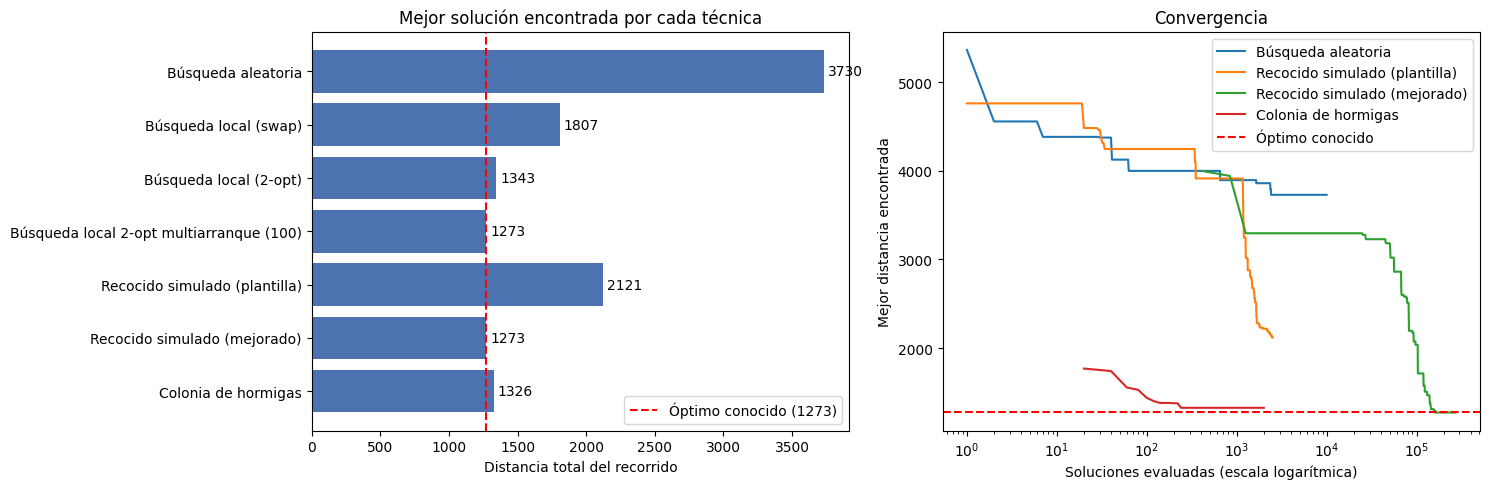

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1: mejor distancia por técnica
nombres = list(RESULTADOS)
valores = [RESULTADOS[k]["distancia"] for k in nombres]
barras = ax1.barh(nombres, valores, color="#4C72B0")
ax1.axvline(OPTIMO, color="red", linestyle="--", label=f"Óptimo conocido ({OPTIMO})")
ax1.bar_label(barras, padding=3)
ax1.invert_yaxis()
ax1.set_xlabel("Distancia total del recorrido")
ax1.set_title("Mejor solución encontrada por cada técnica")
ax1.legend(loc="lower right")

# Gráfico 2: convergencia frente al número de soluciones evaluadas
ax2.plot(range(1, len(hist_aleatoria) + 1), hist_aleatoria, label="Búsqueda aleatoria")
ax2.plot(range(1, len(hist_rs_orig) + 1), hist_rs_orig, label="Recocido simulado (plantilla)")
ax2.plot(*zip(*info_rs["historial"]), label="Recocido simulado (mejorado)")
ax2.plot(*zip(*hist_aco), label="Colonia de hormigas")
ax2.axhline(OPTIMO, color="red", linestyle="--", label="Óptimo conocido")
ax2.set_xscale("log")
ax2.set_xlabel("Soluciones evaluadas (escala logarítmica)")
ax2.set_ylabel("Mejor distancia encontrada")
ax2.set_title("Convergencia")
ax2.legend()

plt.tight_layout()
plt.show()

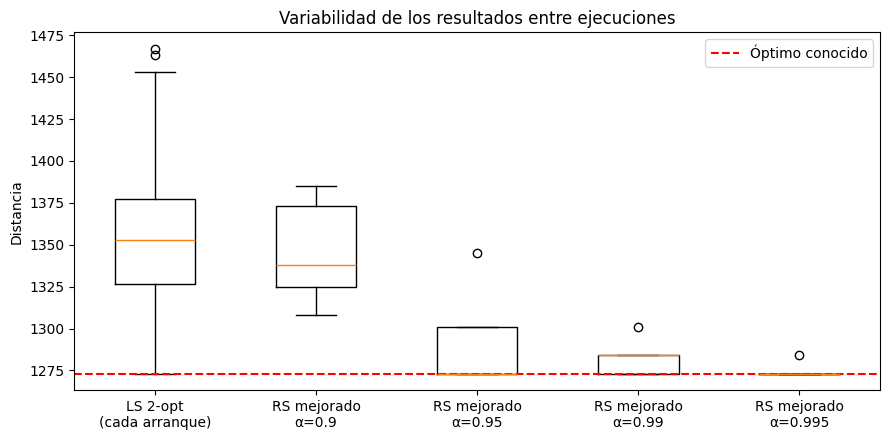

In [16]:
# Robustez: distribución de resultados de los métodos estocásticos con varias ejecuciones
plt.figure(figsize=(9, 4.5))
datos = [dist_arranques] + [sensibilidad[a] for a in sensibilidad]
etiquetas = ["LS 2-opt\n(cada arranque)"] + [f"RS mejorado\nα={a}" for a in sensibilidad]
plt.boxplot(datos)
plt.xticks(range(1, len(etiquetas) + 1), etiquetas)
plt.axhline(OPTIMO, color="red", linestyle="--", label="Óptimo conocido")
plt.ylabel("Distancia")
plt.title("Variabilidad de los resultados entre ejecuciones")
plt.legend()
plt.tight_layout()
plt.show()

# 6. Conclusiones

**Búsqueda aleatoria.** Con 10 000 soluciones al azar la mejor distancia fue **3730** (gap del 193 %), y una solución aleatoria típica mide en torno a **4830**. El espacio de búsqueda tiene 41!/2 ≈ 1.7·10⁴⁹ recorridos distintos, por lo que muestrear sin usar información del problema es inútil en la práctica: solo sirve como línea base.

**Búsqueda local.** El operador de vecindad es determinante. Partiendo de la misma solución inicial, el vecindario de intercambio de la plantilla se estanca en **1807**, mientras que el **2-opt real** llega a **1343** (gap del 5.5 %) y además es del orden de 10 veces más rápido gracias a la evaluación incremental. Una sola ejecución queda atrapada en un óptimo local; con **multiarranque** (100 búsquedas locales desde soluciones aleatorias, 0.6 s) se alcanzó el **óptimo conocido 1273**, aunque solo 3 de los 100 arranques llegaron a él (media de 1354): la calidad depende mucho del punto de partida.

**Recocido simulado.** La versión de la plantilla obtiene **2121**, peor incluso que la búsqueda local, porque su temperatura inicial (10⁷) hace que gran parte de sus ~2 500 iteraciones sean un paseo aleatorio. Al calibrar T₀ con la tasa de aceptación (≈ 330), hacer L iteraciones por temperatura, usar el vecino 2-opt y pulir el resultado, el algoritmo alcanza el **óptimo 1273**. El estudio de sensibilidad muestra el compromiso entre calidad y tiempo: un enfriamiento rápido (α = 0.90) se comporta casi como una búsqueda local (media 1345.8, nunca llega al óptimo), mientras que uno lento (α = 0.995) es el más robusto (media 1275.2, óptimo en 4 de 5 ejecuciones) a costa de duplicar el tiempo respecto a α = 0.99.

**Colonia de hormigas (no evaluable).** Con la regla de transición probabilística, la evaporación corregida y el refuerzo elitista se obtuvo **1326** (gap del 4.2 %), frente a 3545 de la plantilla, que elegía los nodos de forma uniforme. Hibridarla con una búsqueda local 2-opt sobre cada recorrido sería la mejora natural.

**Conclusión general.** Las técnicas que explotan la estructura del problema (vecindario 2-opt) superan ampliamente a la exploración ciega, y añadir un mecanismo para escapar de los óptimos locales (multiarranque o aceptación probabilística del recocido) permite llegar al óptimo de swiss42 en menos de un segundo. En una instancia tan pequeña el multiarranque es suficiente; en instancias mayores la probabilidad de que un arranque aleatorio caiga en el óptimo disminuye, y una metaheurística bien parametrizada como el recocido simulado cobra más importancia. En todos los casos, al ser algoritmos estocásticos, conviene evaluarlos con varias ejecuciones y no con un único resultado.